In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json
import sinter
import scipy

In [2]:
stats = sinter.stats_from_csv_files('data.csv')
for stat in stats:
    print(stat)

    122000,         5,         0,   659.5,lut,7dc7ce5682f727b4ec74b87f33a58b859cdb8416965983aefe5f31bf3ba34d40,"{""basis"":""X"",""code"":""7_1_3"",""max_error_weight"":3,""per"":0.0005}",
    122000,        10,         0,   677.6,lut,2c576d666df2a8608f4ed633cbdf755c44c8c4161f88e05d18b981c67ed7b2d5,"{""basis"":""X"",""code"":""7_1_3"",""max_error_weight"":3,""per"":0.0006}",
    122000,        30,         0,   665.8,lut,d8ffd01a1ee948b0f980f7a8faff1883ddd734c41542cacb1dff6c90af576873,"{""basis"":""Z"",""code"":""7_1_3"",""max_error_weight"":3,""per"":0.0005}",
    122000,        42,         0,   669.1,lut,cda5c41f1977e2598e0009638f1d87b7271e1069910def37424d794cb163e0d8,"{""basis"":""Z"",""code"":""7_1_3"",""max_error_weight"":3,""per"":0.0006}",
    122000,        21,         0,   667.4,lut,3c763a172382dd67dc2e4ba953aa798bd99d3b157760bb765706d5207fc3f71d,"{""basis"":""X"",""code"":""16_4_3"",""max_error_weight"":3,""per"":0.0007}",
    122000,        11,         0,   702.3,lut,174cfb53

In [ ]:
def plot_linefit(ax, d, pers, lers, x_values):
    def fit_func(x, c0, c1, c2):
        return x**((d+1)/2) * np.e ** (c0 + c1 * x + c2 * x**2)

    popt, pcov = scipy.optimize.curve_fit(fit_func, pers, lers)
    fitted_values = fit_func(x_values, *popt)
    ax.plot(x_values, fitted_values)
    ax.plot(pers, lers, 'o', linestyle='None')
    return (find_and_plot_crossing(ax, x_values, popt, fit_func))


def find_and_plot_crossing(ax, x_values, popt, fit_func,):
    try:
        root_result = scipy.optimize.root_scalar(
            lambda x: fit_func(x, *popt) - x,
            bracket=[min(x_values), max(x_values)]
        )
        if root_result.converged:
            print(f"Line crosses y=x at x = {root_result.root:.6f}")
            ax.axvline(x=root_result.root, color='r',
                       linestyle='--', alpha=0.5)
            ax.text(root_result.root, root_result.root,
                    f'   $x =$ {root_result.root:.2e}',
                    rotation=90, verticalalignment='bottom',
                    horizontalalignment='right', )
    except ValueError as e:
        print(f"Error finding crossing point: {e}")
    return root_result.root if root_result.converged else None


def plot_bb_30_4_5(ax, pers, factor):
    # uses 35 qubits.
    c0 = 12.869
    c1 = -340.43
    c2 = 15878
    d = 5

    def fit_func(x, c0, c1, c2):
        return x**((d+1)/2) * np.e ** (c0 + c1 * x + c2 * x**2)*factor
    ax.plot(pers, fit_func(pers, c0, c1, c2), label=str(factor) + ' rounds',)

    pseudo_threshold = find_and_plot_crossing(ax, pers, [c0, c1, c2], fit_func)
    ax.set_title("[30,4,5]")
    return (pseudo_threshold)


def plot_bb_48_4_7(ax, pers, factor):
    c0 = 18.256
    c1 = -260.44
    c2 = 680.65
    d = 7

    def fit_func(x, c0, c1, c2):
        return x**((d+1)/2) * np.e ** (c0 + c1 * x + c2 * x**2)*factor
    ax.plot(pers, fit_func(pers, c0, c1, c2), label=str(factor) + ' rounds',)
    pseudo_threshold = find_and_plot_crossing(ax, pers, [c0, c1, c2], fit_func)
    ax.set_title("[48,4,7]")
    return (pseudo_threshold)

In [56]:
from typing import List


def group_by(items,
             key,
             ):

    result = {}

    for item in items:
        curve_id = key(item)
        result.setdefault(curve_id, []).append(item)

    return result


def plot_code(ax, code_name, x_values):
    ler_dict = {}
    # first find all pers

    stats7_1_3_X = [
        stat for stat in stats if stat.json_metadata['code'] == code_name and stat.json_metadata['basis'] == 'X' and stat.json_metadata['max_error_weight'] == 3]
    pers = [stat.json_metadata['per'] for stat in stats7_1_3_X]

    for per in pers:
        # get X basis stat
        stats7_1_3_X_per = [
            stat for stat in stats7_1_3_X if stat.json_metadata['per'] == per and stat.json_metadata['max_error_weight'] == 3]
        stats7_1_3_Z_per = [
            stat for stat in stats if stat.json_metadata['code'] == code_name and stat.json_metadata['basis'] == 'Z' and stat.json_metadata['per'] == per and stat.json_metadata['max_error_weight'] == 3]
        ler_dict[per] = (stats7_1_3_X_per[-1].errors + stats7_1_3_Z_per[-1].errors) / \
            (stats7_1_3_X_per[-1].shots + stats7_1_3_Z_per[-1].shots)

    pers = sorted(ler_dict.keys())
    lers = [ler_dict[per] for per in pers]
    ax.set_title(f"[{code_name.replace('_', ',')}]")
    return (plot_linefit(ax, int(code_name[-1]), pers, lers, x_values))


# plot_code(ax, '7_1_3')
"""
sinter.TaskStats(
    strong_id=strong_id_hash,
    shots=trials,
    errors=int(lers[-1]),
    decoder="lut",
    json_metadata={k: v for k, v in vars(args).items()},
    seconds=end_time - start_time,
)
"""

'\nsinter.TaskStats(\n    strong_id=strong_id_hash,\n    shots=trials,\n    errors=int(lers[-1]),\n    decoder="lut",\n    json_metadata={k: v for k, v in vars(args).items()},\n    seconds=end_time - start_time,\n)\n'

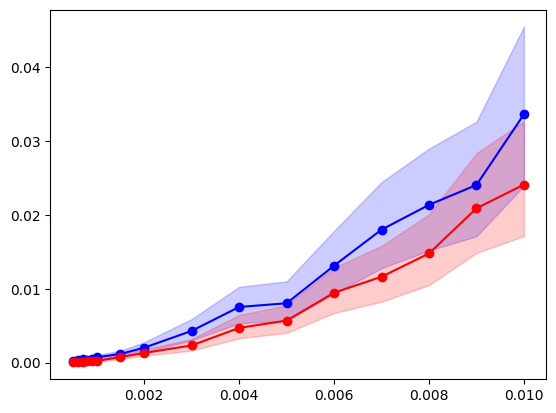

In [60]:
fig, ax = plt.subplots()
sinter.plot_error_rate(
    ax=ax, stats=stats, x_func=lambda stats: stats.json_metadata['per'], filter_func=lambda stats: stats.json_metadata['basis'] == 'Z' and stats.json_metadata['code'] == '7_1_3', plot_args_func=lambda stats, curve_id: {'color': 'blue', 'label': '7_1_3 Z'})
sinter.plot_error_rate(
    ax=ax, stats=stats, x_func=lambda stats: stats.json_metadata['per'], filter_func=lambda stats: stats.json_metadata['basis'] == 'X' and stats.json_metadata['code'] == '7_1_3', plot_args_func=lambda stats, curve_id: {'color': 'red', 'label': '7_1_3 X'})

Line crosses y=x at x = 0.002267
Line crosses y=x at x = 0.001336
Line crosses y=x at x = 0.002929


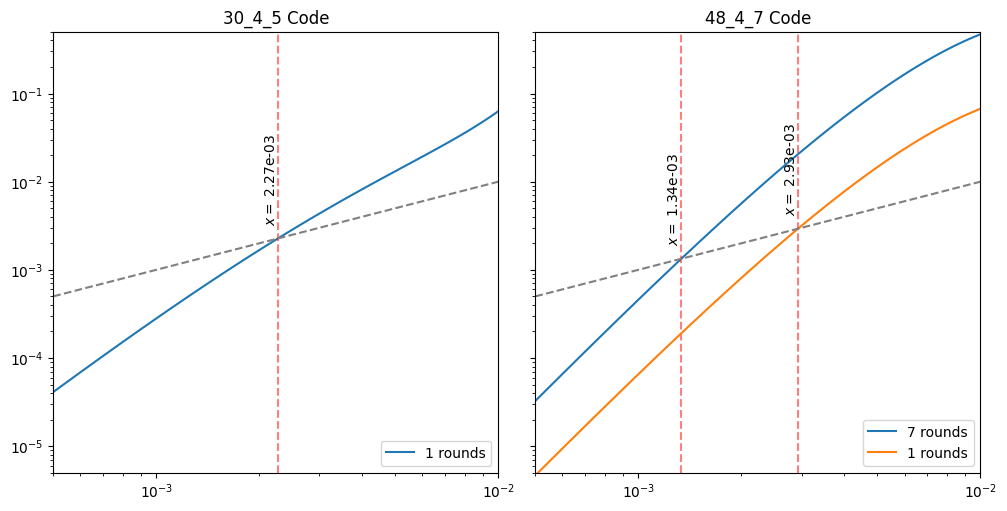

In [ ]:
import matplotlib.pyplot as plt
x_min, x_max = 5e-4, 1e-2
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
fig.tight_layout()
pseudothresholds = dict()
for code, n_qubits in zip(['30_4_4', '48_4_7', '7_1_3', '16_4_3', '18_6_3', '16_4_4', '27_9_3', '12_2_3'], [35, 54, 15, 35, 40, 38, 58, 28]):
    pseudothresholds[code] = dict()
    pseudothresholds[code]['n_qubits'] = n_qubits

plot_bb_30_4_5(
    axes[0], pers=np.linspace(0.0001, 0.01, 100), factor=5)

pseudothresholds['30_4_4']['pseudo'] = plot_bb_30_4_5(
    axes[0], pers=np.linspace(0.0001, 0.01, 100), factor=1)
plot_bb_48_4_7(
    axes[1], pers=np.linspace(0.0001, 0.01, 100), factor=7)
pseudothresholds['48_4_7']['pseudo'] = plot_bb_48_4_7(
    axes[1], pers=np.linspace(0.0001, 0.01, 100), factor=1)

for ax in axes:
    ax.plot([x_min, x_max], [x_min, x_max], '--', color='gray')
    ax.legend(loc='lower right')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(5e-6, 5e-1)
    ax.loglog()

Line crosses y=x at x = 0.002784
Line crosses y=x at x = 0.002947
Line crosses y=x at x = 0.002886
Line crosses y=x at x = 0.004175
Line crosses y=x at x = 0.005355
Line crosses y=x at x = 0.002994


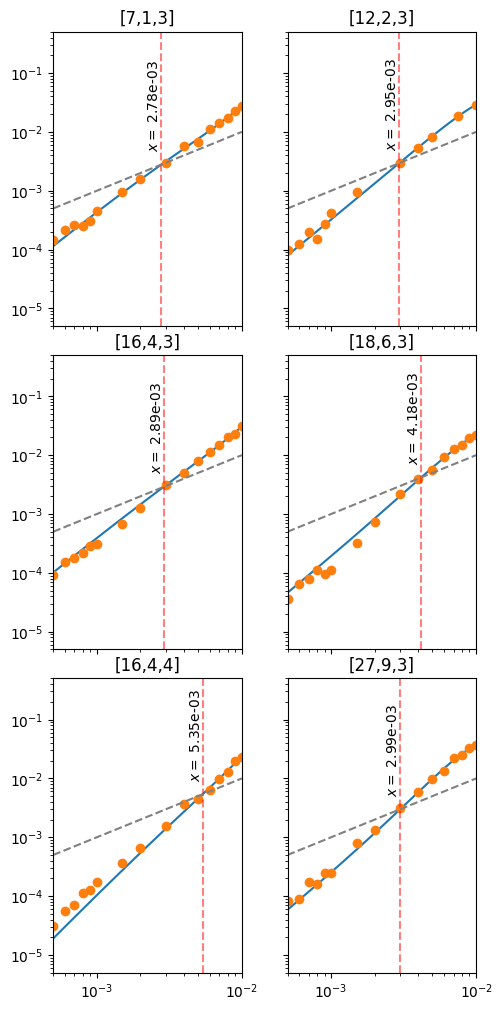

In [58]:


import matplotlib.pyplot as plt
x_min, x_max = 5e-4, 1e-2
fig, axes = plt.subplots(3, 2, figsize=(5, 10), sharey=True, sharex=True)
fig.tight_layout()


codes = [['7_1_3', '12_2_3'], ['16_4_3', '18_6_3'], ['16_4_4', '27_9_3']]
for i, code_row in enumerate(codes):
    for j, code in enumerate(code_row):
        pseudothresholds[code]['pseudo'] = plot_code(
            axes[i, j], code, np.linspace(0.0001, 0.01, 100))

for ax in np.ravel(axes):
    ax.plot([x_min, x_max], [x_min, x_max], '--', color='gray')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(5e-6, 5e-1)
    ax.loglog()

In [ ]:
"""
sinter.plot_error_rate(
    ax=axes[2], stats=stats, x_func=lambda stats: stats.json_metadata['per'], filter_func=lambda stats: stats.json_metadata['basis'] == 'Z' and stats.json_metadata['code'] == '7_1_3', plot_args_func=lambda stats, curve_id: {'color': 'blue', 'label': '7_1_3 Z'})
sinter.plot_error_rate(
    ax=axes[2], stats=stats, x_func=lambda stats: stats.json_metadata['per'], filter_func=lambda stats: stats.json_metadata['basis'] == 'X' and stats.json_metadata['code'] == '7_1_3', plot_args_func=lambda stats, curve_id: {'color': 'red', 'label': '7_1_3 X'})


sinter.plot_error_rate(
    ax=axes[3], stats=stats, x_func=lambda stats: stats.json_metadata['per'], filter_func=lambda stats: stats.json_metadata['basis'] == 'Z' and stats.json_metadata['code'] == '16_4_3', plot_args_func=lambda stats, curve_id: {'color': 'green', 'label': '16_4_3 Z'})
sinter.plot_error_rate(
    ax=axes[3], stats=stats, x_func=lambda stats: stats.json_metadata['per'], filter_func=lambda stats: stats.json_metadata['basis'] == 'X' and stats.json_metadata['code'] == '16_4_3', plot_args_func=lambda stats, curve_id: {'color': 'purple', 'label': '16_4_3 X'})
"""

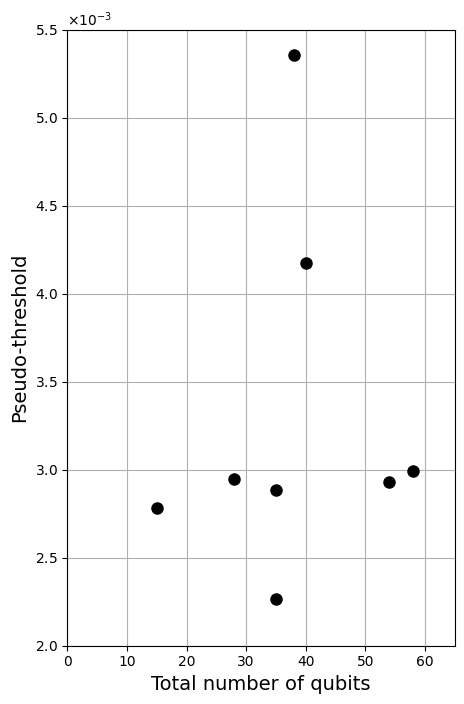

In [6]:
fig2, ax2 = plt.subplots(figsize=(5, 8))

for code, data in pseudothresholds.items():
    if 'pseudo' in data and data['pseudo'] is not None:
        ax2.plot(data['n_qubits'],
                 data['pseudo'], 'o', label=code, color='black', markersize=8)

ax2.set_ylabel('Pseudo-threshold', fontsize=14)
ax2.set_xlabel('Total number of qubits', fontsize=14)
ax2.grid()
ax2.yaxis.set_major_formatter(plt.ScalarFormatter(useMathText=True))
ax2.set_xlim(0, 65)
ax2.set_ylim(0.002, 0.0055)
ax2.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))
fig2.savefig("plot.svg")

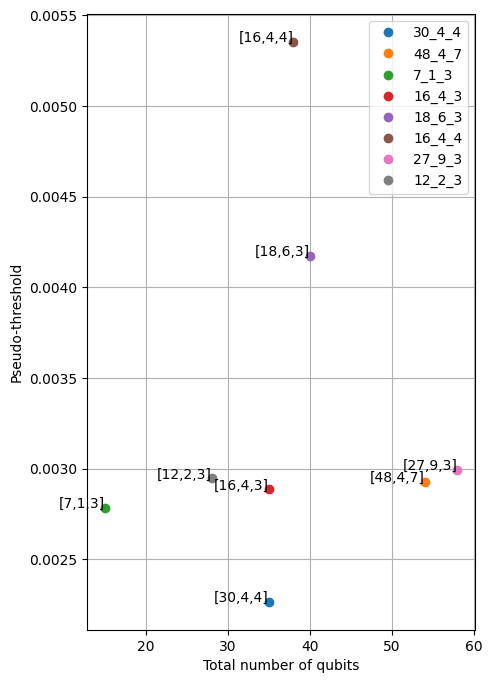

In [ ]:
fig2, ax2 = plt.subplots(figsize=(5, 8))

for code, data in pseudothresholds.items():
    if 'pseudo' in data and data['pseudo'] is not None:
        ax2.plot(data['n_qubits'],
                 data['pseudo'], 'o', label=code)
        ax2.text(data['n_qubits'], data['pseudo'], '[' + code.replace('_', ',') + ']',
                 fontsize=10, horizontalalignment='right')


ax2.set_ylabel('Pseudo-threshold')
ax2.set_xlabel('Total number of qubits')
ax2.grid()
ax2.legend()

[]

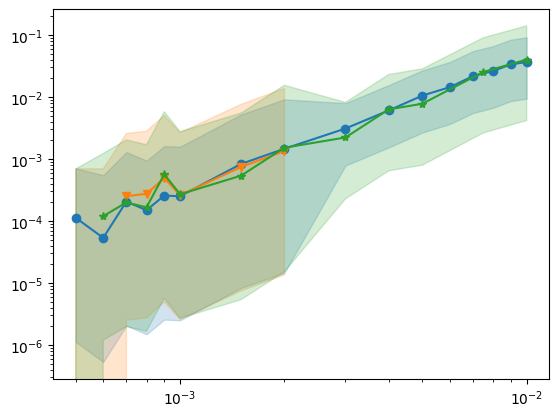

In [8]:
fig2, ax3 = plt.subplots()

sinter.plot_error_rate(
    ax=ax3, stats=stats, group_func=lambda stats: stats.json_metadata['max_error_weight'], x_func=lambda stats: stats.json_metadata['per'], filter_func=lambda stats: stats.json_metadata['basis'] == 'Z' and stats.json_metadata['code'] == '27_9_3')  # , plot_args_func=lambda stats, curve_id: {'color': 'blue', 'label': '7_1_3 Z'})
ax3.loglog()

In [9]:
def translate_data(data, wer=False):
    pers = []
    for per in data.keys():
        pers.append(float(per))
    pers.sort()

    lers = []
    for per in pers:
        if wer:
            lers.append(2*data[str(per)][0][-1])
#            lers.append(1 - (1-data[str(per)][0][-1])**(1/4))
        else:
            lers.append(data[str(per)][0][-1])
    return (pers, lers)


steane_pers, steane_lers = translate_data(steane_json)
two_steane_pers, two_steane_lers = translate_data(two_steane_json)
hex_code_pers, hex_code_lers = translate_data(sixteen_json, True)
eighteen_pers, eighteen_lers = translate_data(eighteen_json, True)
print(hex_code_pers, hex_code_lers)
# print(steane_lers, two_steane_lers)

NameError: name 'steane_json' is not defined

In [ ]:
def bb_30_4_5(pers):
    # uses 35 qubits.
    c0 = 12.869
    c1 = -340.43
    c2 = 15878
#    d = 10
    return [per**(6/2) * np.e ** (c0 + c1 * per + c2 * per**2) for per in pers]

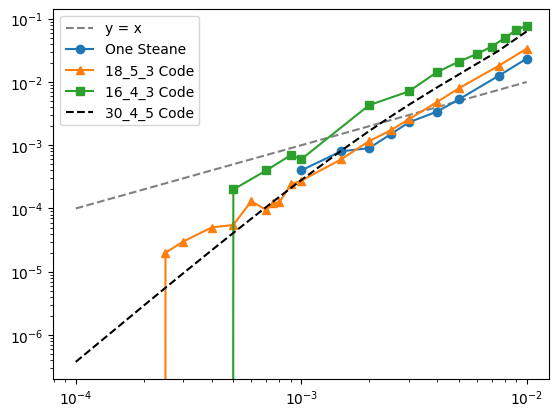

In [ ]:
plt.plot(eighteen_pers, eighteen_pers,
         linestyle='--', color='gray', label='y = x')
plt.plot(steane_pers, steane_lers, marker='o', label='One Steane')
# plt.plot(two_steane_pers, two_steane_lers,
#         marker='x', label='Two Steane')
plt.plot(eighteen_pers, eighteen_lers, marker='^', label='18_6_3 Code')
plt.plot(hex_code_pers, hex_code_lers, marker='s', label='16_4_3 Code')
plt.plot(eighteen_pers, bb_30_4_5(eighteen_pers), label="30_4_5 Code",
         color='black', linestyle='--')
# plt.plot(hex_code_pers, hex_code_lers, marker='s', label='16_4_3 Code')
plt.xscale('log')
plt.yscale('log')

plt.legend()
plt.show()